In [5]:
!pip install dowhy econml lightgbm

Defaulting to user installation because normal site-packages is not writeable


In [6]:
import pandas as pd, numpy as np

df = pd.read_csv("hillstrom.csv")
df["treatment"] = (df["segment"] != "No E-Mail").astype(int)
df = df.drop(columns=["history_segment", "segment"])
df = pd.get_dummies(df, columns=["zip_code", "channel"], drop_first=True, dtype=int)

confounders = [c for c in df.columns if c not in ["treatment", "visit", "conversion", "spend"]]
print(confounders)
print(df["treatment"].value_counts())

['recency', 'history', 'mens', 'womens', 'newbie', 'zip_code_Surburban', 'zip_code_Urban', 'channel_Phone', 'channel_Web']
treatment
1    42694
0    21306
Name: count, dtype: int64


In [10]:
import networkx as nx
nx.algorithms.d_separated = nx.algorithms.is_d_separator

from dowhy import CausalModel

model = CausalModel(
    data=df,
    treatment="treatment",
    outcome="conversion",
    common_causes=confounders
)

estimand = model.identify_effect(proceed_when_unidentifiable=True)
print(estimand)

Estimand type: nonparametric-ate

### Estimand : 1
Estimand name: backdoor
Estimand expression:
     d                                                                         ↪
────────────(E[conversion|mens,channel_Web,newbie,zip_code_Surburban,zip_code_ ↪
d[treatment]                                                                   ↪

↪                                             
↪ Urban,history,channel_Phone,recency,womens])
↪                                             
Estimand assumption 1, Unconfoundedness: If U→{treatment} and U→conversion then P(conversion|treatment,mens,channel_Web,newbie,zip_code_Surburban,zip_code_Urban,history,channel_Phone,recency,womens,U) = P(conversion|treatment,mens,channel_Web,newbie,zip_code_Surburban,zip_code_Urban,history,channel_Phone,recency,womens)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!



In [11]:
import networkx as nx
nx.algorithms.d_separated = nx.algorithms.is_d_separator

In [12]:
print(df.shape)
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df.describe())
print("Conversion rate:", df["conversion"].mean())

(64000, 13)
Missing values:
 recency               0
history               0
mens                  0
womens                0
newbie                0
visit                 0
conversion            0
spend                 0
treatment             0
zip_code_Surburban    0
zip_code_Urban        0
channel_Phone         0
channel_Web           0
dtype: int64
Duplicate rows: 6988
            recency       history          mens        womens        newbie  \
count  64000.000000  64000.000000  64000.000000  64000.000000  64000.000000   
mean       5.763734    242.085656      0.551031      0.549719      0.502250   
std        3.507592    256.158608      0.497393      0.497526      0.499999   
min        1.000000     29.990000      0.000000      0.000000      0.000000   
25%        2.000000     64.660000      0.000000      0.000000      0.000000   
50%        6.000000    158.110000      1.000000      1.000000      1.000000   
75%        9.000000    325.657500      1.000000      1.000000      1.000

In [13]:
import statsmodels.api as sm

Xc = sm.add_constant(df[["treatment"] + confounders].astype(float))
ols = sm.OLS(df["conversion"].astype(float), Xc).fit()
print("Average Treatment Effect:", ols.params["treatment"])
print("p-value:", ols.pvalues["treatment"])

Average Treatment Effect: 0.004939857438799675
p-value: 4.623834970157697e-10


In [14]:
from econml.dml import LinearDML
from lightgbm import LGBMRegressor, LGBMClassifier

Y = df["conversion"].values
T = df["treatment"].values
X = df[confounders].astype(float).values

dml = LinearDML(
    model_y=LGBMRegressor(n_estimators=100, verbose=-1),
    model_t=LGBMClassifier(n_estimators=100, verbose=-1),
    discrete_treatment=True,
    random_state=42
)
dml.fit(Y, T, X=X)

df["ITE"] = dml.effect(X)
print("DML Average Treatment Effect:", df["ITE"].mean())
print(df["ITE"].describe())

DML Average Treatment Effect: 0.004980021615338001
count    64000.000000
mean         0.004980
std          0.002918
min         -0.000585
25%          0.002919
50%          0.004637
75%          0.006489
max          0.019263
Name: ITE, dtype: float64


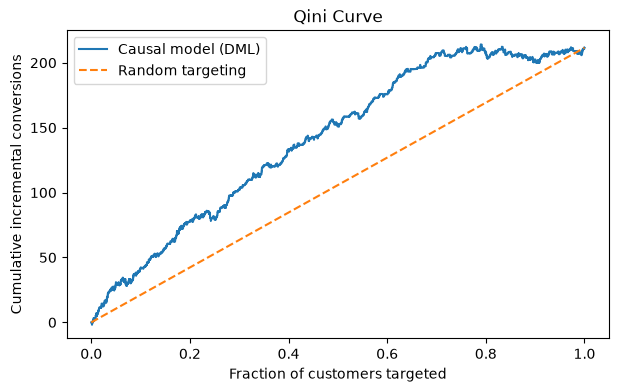

In [15]:
import numpy as np
import matplotlib.pyplot as plt

order = np.argsort(-df["ITE"].values)
y = df["conversion"].values[order]
t = df["treatment"].values[order]

nt = np.cumsum(t)
nc = np.cumsum(1 - t)
yt = np.cumsum(y * t)
yc = np.cumsum(y * (1 - t))
qini = yt - yc * np.where(nc > 0, nt / np.maximum(nc, 1), 0)

x = np.arange(1, len(y) + 1) / len(y)
plt.figure(figsize=(7, 4))
plt.plot(x, qini, label="Causal model (DML)")
plt.plot([0, 1], [0, qini[-1]], "--", label="Random targeting")
plt.xlabel("Fraction of customers targeted")
plt.ylabel("Cumulative incremental conversions")
plt.title("Qini Curve")
plt.legend()
plt.show()

In [16]:
rng = np.random.default_rng(42)
T_fake = rng.permutation(T)

dml_placebo = LinearDML(
    model_y=LGBMRegressor(n_estimators=100, verbose=-1),
    model_t=LGBMClassifier(n_estimators=100, verbose=-1),
    discrete_treatment=True,
    random_state=42
)
dml_placebo.fit(Y, T_fake, X=X)
print("Placebo ATE (should be ~0):", dml_placebo.effect(X).mean())
print("Real ATE:", df["ITE"].mean())

Placebo ATE (should be ~0): 0.0007530317627650581
Real ATE: 0.004980021615338001


In [18]:
from scipy.optimize import linprog

cost_per_email = 0.10
budget = 1000
value = df.loc[df["conversion"] == 1, "spend"].mean()

gain = df["ITE"].values * value - cost_per_email
res = linprog(
    c=-gain,
    A_ub=[np.full(len(df), cost_per_email)],
    b_ub=[budget],
    bounds=(0, 1),
    method="highs"
)
df["send_email"] = (res.x > 0.5).astype(int)

n = df["send_email"].sum()
opt_gain = (df.loc[df["send_email"] == 1, "ITE"] * value).sum()
rand_gain = df["ITE"].mean() * value * n
print("Customers selected:", n)
print("Expected extra revenue (optimized): $", round(opt_gain, 2))
print("Expected extra revenue (random targeting): $", round(rand_gain, 2))

Customers selected: 10000
Expected extra revenue (optimized): $ 11811.65
Expected extra revenue (random targeting): $ 5794.93


In [19]:
saving = opt_gain - rand_gain
print(f"This strategy earns ${saving:.2f} more than random targeting with the same ${budget} budget.")

This strategy earns $6016.72 more than random targeting with the same $1000 budget.


In [20]:
from scipy.stats import ks_2samp

half = len(df) // 2
old, new = df.iloc[:half], df.iloc[half:]
for col in ["recency", "history"]:
    stat, p = ks_2samp(old[col], new[col])
    print(col, "-> DRIFT WARNING" if p < 0.05 else "-> stable", "(p =", round(p, 4), ")")

recency -> stable (p = 0.9735 )
history -> stable (p = 0.9825 )


In [21]:
cols = ["recency", "history", "mens", "womens", "newbie", "treatment", "conversion", "ITE"]
df[cols].to_csv("ite_scores.csv", index=False)
print("Saved ite_scores.csv")

Saved ite_scores.csv


In [22]:
%%writefile app.py
import streamlit as st, pandas as pd, numpy as np
import plotly.express as px, plotly.graph_objects as go

st.set_page_config(page_title="EconoCausal", layout="wide")
st.title("EconoCausal: Causal Uplift & Budget Allocation")

up = st.sidebar.file_uploader("Upload ITE scores CSV", type="csv")
df = pd.read_csv(up) if up else pd.read_csv("ite_scores.csv")
budget = st.sidebar.number_input("Budget ($)", 100, 100000, 1000, 100)
cost = st.sidebar.number_input("Cost per email ($)", 0.01, 5.0, 0.10, 0.01)
value = st.sidebar.number_input("Revenue per conversion ($)", 1.0, 500.0, 116.0, 1.0)
lo, hi = int(df.recency.min()), int(df.recency.max())
r = st.sidebar.slider("Recency (months)", lo, hi, (lo, hi))
f = df[df.recency.between(*r)]

c1, c2 = st.columns(2)
c1.metric("Customers", f"{len(f):,}")
c2.metric("Average ITE", f"{f.ITE.mean():.5f}")

st.plotly_chart(px.histogram(f, x="ITE", nbins=50, title="ITE distribution"), use_container_width=True)

o = f.sort_values("ITE", ascending=False)
y, t = o.conversion.values, o.treatment.values
nt, nc = np.cumsum(t), np.cumsum(1 - t)
q = np.cumsum(y * t) - np.cumsum(y * (1 - t)) * np.where(nc > 0, nt / np.maximum(nc, 1), 0)
x = np.arange(1, len(y) + 1) / len(y)
fig = go.Figure()
fig.add_scatter(x=x, y=q, name="Causal model")
fig.add_scatter(x=[0, 1], y=[0, q[-1]], name="Random", line=dict(dash="dash"))
fig.update_layout(title="Qini / Uplift curve", xaxis_title="Fraction targeted", yaxis_title="Incremental conversions")
st.plotly_chart(fig, use_container_width=True)

n = int(budget / cost)
alloc = o.head(n)
opt = (alloc.ITE * value).sum()
rnd = f.ITE.mean() * value * len(alloc)
st.success(f"This strategy earns ${opt - rnd:,.2f} more than random targeting with the same ${budget:,} budget.")
st.subheader("Allocation: customers to email")
st.dataframe(alloc.head(100))

Overwriting app.py


In [26]:
import pandas as pd, numpy as np

raw = pd.read_csv("hillstrom.csv")
df_d = raw.drop(columns=["history_segment", "segment", "visit", "spend", "conversion"]).copy()
df_d = pd.get_dummies(df_d, columns=["zip_code", "channel"], drop_first=True, dtype=int)
feats_d = list(df_d.columns)

rng = np.random.default_rng(42)
h = ((df_d["history"] - df_d["history"].mean()) / df_d["history"].std()).clip(-2, 2)
rec = ((df_d["recency"] - df_d["recency"].mean()) / df_d["recency"].std()).clip(-2, 2)

logits = np.column_stack([
    np.zeros(len(df_d)),
    0.5 * h - 0.3 * rec - 0.3,
    0.9 * h - 0.5 * rec - 0.8,
])
p = np.exp(logits)
p = p / p.sum(axis=1, keepdims=True)
u = rng.random(len(df_d))[:, None]
level = (u > p.cumsum(axis=1)).sum(axis=1)
df_d["discount"] = pd.Series(level).map({0: 0, 1: 10, 2: 20}).values

print(df_d["discount"].value_counts())

discount
0     30009
10    20220
20    13771
Name: count, dtype: int64


In [32]:
import pandas as pd, numpy as np

raw = pd.read_csv("hillstrom.csv")
df_d = raw.drop(columns=["history_segment", "segment", "visit", "spend", "conversion"]).copy()
df_d = pd.get_dummies(df_d, columns=["zip_code", "channel"], drop_first=True, dtype=int)
feats_d = list(df_d.columns)

rng = np.random.default_rng(42)
h = ((df_d["history"] - df_d["history"].mean()) / df_d["history"].std()).clip(-2, 2)
rec = ((df_d["recency"] - df_d["recency"].mean()) / df_d["recency"].std()).clip(-2, 2)

logits = np.column_stack([
    np.zeros(len(df_d)),
    0.5 * h - 0.3 * rec - 0.3,
    0.9 * h - 0.5 * rec - 0.8,
])
p = np.exp(logits)
p = p / p.sum(axis=1, keepdims=True)
u = rng.random(len(df_d))[:, None]
level = (u > p.cumsum(axis=1)).sum(axis=1)
df_d["discount"] = pd.Series(level).map({0: 0, 1: 10, 2: 20}).values

print(df_d["discount"].value_counts())

discount
0     30009
10    20220
20    13771
Name: count, dtype: int64


In [33]:
base = 0.012 + 0.004 * h
tau10 = 0.004 + 0.012 * df_d["newbie"] + 0.008 * (df_d["recency"] <= 6)
tau20 = tau10 + 0.004 + 0.004 * df_d["newbie"]

df_d["true_tau10"] = tau10.values
df_d["true_tau20"] = tau20.values

p_conv = base.values + np.where(df_d["discount"] == 10, tau10, np.where(df_d["discount"] == 20, tau20, 0))
df_d["conversion"] = (rng.random(len(df_d)) < np.clip(p_conv, 0, 1)).astype(int)

print(df_d.groupby("discount")["conversion"].mean())

discount
0     0.011763
10    0.027102
20    0.035219
Name: conversion, dtype: float64


In [34]:
from econml.dml import LinearDML
from lightgbm import LGBMRegressor, LGBMClassifier

Xd = df_d[feats_d].astype(float).values
Yd = df_d["conversion"].values
disc = df_d["discount"].values

def fit_effect(level):
    m = np.isin(disc, [0, level])
    dml = LinearDML(
        model_y=LGBMRegressor(n_estimators=100, verbose=-1),
        model_t=LGBMClassifier(n_estimators=100, verbose=-1),
        discrete_treatment=True,
        random_state=42
    )
    dml.fit(Yd[m], (disc[m] == level).astype(int), X=Xd[m])
    return dml.effect(Xd)

df_d["ITE_10"] = fit_effect(10)
df_d["ITE_20"] = fit_effect(20)

print("Estimated avg effect of $10:", df_d["ITE_10"].mean(), "| True:", df_d["true_tau10"].mean())
print("Estimated avg effect of $20:", df_d["ITE_20"].mean(), "| True:", df_d["true_tau20"].mean())
print("Correlation ($10):", np.corrcoef(df_d["ITE_10"], df_d["true_tau10"])[0, 1])
print("Correlation ($20):", np.corrcoef(df_d["ITE_20"], df_d["true_tau20"])[0, 1])

Estimated avg effect of $10: 0.013230308943869824 | True: 0.014600125000000002
Estimated avg effect of $20: 0.015571085882016764 | True: 0.020609125000000006
Correlation ($10): 0.8850756972390152
Correlation ($20): 0.6875437550614378


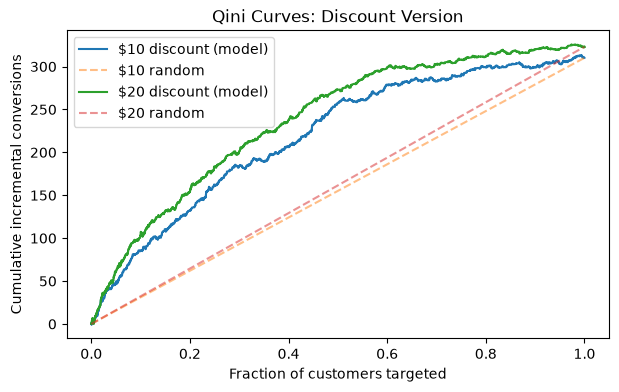

In [35]:
import matplotlib.pyplot as plt

def qini_curve(ite, level):
    m = np.isin(disc, [0, level])
    o = np.argsort(-ite[m])
    y = Yd[m][o]
    t = (disc[m][o] == level).astype(int)
    nt, nc = np.cumsum(t), np.cumsum(1 - t)
    q = np.cumsum(y * t) - np.cumsum(y * (1 - t)) * np.where(nc > 0, nt / np.maximum(nc, 1), 0)
    return np.arange(1, len(y) + 1) / len(y), q

plt.figure(figsize=(7, 4))
for lvl, col in [(10, "ITE_10"), (20, "ITE_20")]:
    x, q = qini_curve(df_d[col].values, lvl)
    plt.plot(x, q, label=f"${lvl} discount (model)")
    plt.plot([0, 1], [0, q[-1]], "--", alpha=0.5, label=f"${lvl} random")
plt.xlabel("Fraction of customers targeted")
plt.ylabel("Cumulative incremental conversions")
plt.title("Qini Curves: Discount Version")
plt.legend()
plt.show()

In [36]:
rng2 = np.random.default_rng(7)
m = np.isin(disc, [0, 20])
T_fake = rng2.permutation((disc[m] == 20).astype(int))

dml_p = LinearDML(
    model_y=LGBMRegressor(n_estimators=100, verbose=-1),
    model_t=LGBMClassifier(n_estimators=100, verbose=-1),
    discrete_treatment=True,
    random_state=42
)
dml_p.fit(Yd[m], T_fake, X=Xd[m])
print("Placebo effect ($20, should be ~0):", dml_p.effect(Xd).mean())
print("Real effect ($20):", df_d["ITE_20"].mean())

Placebo effect ($20, should be ~0): -0.0003783172813440444
Real effect ($20): 0.015571085882016764


In [37]:
p0 = df_d.loc[df_d["discount"] == 0, "conversion"].mean()
value = raw.loc[raw["conversion"] == 1, "spend"].mean()
budget = 5000

cost10 = 10 * (p0 + df_d["ITE_10"].values)
cost20 = 20 * (p0 + df_d["ITE_20"].values)
net10 = df_d["ITE_10"].values * value - cost10
net20 = df_d["ITE_20"].values * value - cost20

use20 = net20 > net10
best_net = np.where(use20, net20, net10)
best_cost = np.where(use20, cost20, cost10)
best_disc = np.where(use20, 20, 10)

order = np.argsort(-(best_net / best_cost))
order = order[best_net[order] > 0]
chosen = order[np.cumsum(best_cost[order]) <= budget]

df_d["prescribed_discount"] = 0
df_d.loc[chosen, "prescribed_discount"] = best_disc[chosen]
opt_gain = best_net[chosen].sum()

rr = np.random.default_rng(1).permutation(len(df_d))
rand_pick = rr[np.cumsum(cost10[rr]) <= budget]
rand_gain = net10[rand_pick].sum()

print(df_d["prescribed_discount"].value_counts())
print("Expected net gain (optimized): $", round(opt_gain, 2))
print("Expected net gain (random $10 to everyone): $", round(rand_gain, 2))
print(f"This strategy earns ${opt_gain - rand_gain:,.2f} more than random targeting with the same ${budget:,} budget.")

prescribed_discount
0     50084
10    13916
Name: count, dtype: int64
Expected net gain (optimized): $ 34132.1
Expected net gain (random $10 to everyone): $ 25682.06
This strategy earns $8,450.05 more than random targeting with the same $5,000 budget.


In [38]:
cols = ["recency", "history", "newbie", "mens", "womens", "discount",
        "conversion", "ITE_10", "ITE_20", "prescribed_discount"]
df_d[cols].to_csv("discount_scores.csv", index=False)
print("Saved discount_scores.csv")

Saved discount_scores.csv


In [39]:
%%writefile app_discount.py
import streamlit as st, pandas as pd, numpy as np
import plotly.express as px, plotly.graph_objects as go

st.set_page_config(page_title="EconoCausal Discount", layout="wide")
st.title("EconoCausal: Discount Uplift & Prescription")
df = pd.read_csv("discount_scores.csv")

lvl = st.sidebar.selectbox("Discount level ($)", [10, 20])
col = f"ITE_{lvl}"
lo, hi = int(df.recency.min()), int(df.recency.max())
r = st.sidebar.slider("Recency (months)", lo, hi, (lo, hi))
f = df[df.recency.between(*r)]

c1, c2, c3 = st.columns(3)
c1.metric("Customers", f"{len(f):,}")
c2.metric(f"Avg effect of ${lvl} discount", f"{f[col].mean():.5f}")
c3.metric("Customers prescribed a discount", f"{(f.prescribed_discount > 0).sum():,}")

st.plotly_chart(px.histogram(f, x=col, nbins=50, title=f"ITE distribution (${lvl} vs no discount)"), use_container_width=True)

s = f[f.discount.isin([0, lvl])].sort_values(col, ascending=False)
y = s.conversion.values
t = (s.discount.values == lvl).astype(int)
nt, nc = np.cumsum(t), np.cumsum(1 - t)
q = np.cumsum(y * t) - np.cumsum(y * (1 - t)) * np.where(nc > 0, nt / np.maximum(nc, 1), 0)
x = np.arange(1, len(y) + 1) / len(y)
fig = go.Figure()
fig.add_scatter(x=x, y=q, name="Causal model")
fig.add_scatter(x=[0, 1], y=[0, q[-1]], name="Random", line=dict(dash="dash"))
fig.update_layout(title="Qini / Uplift curve", xaxis_title="Fraction targeted", yaxis_title="Incremental conversions")
st.plotly_chart(fig, use_container_width=True)

st.subheader("Prescription: discount per customer")
counts = f.prescribed_discount.value_counts().rename_axis("discount").reset_index(name="customers")
st.plotly_chart(px.bar(counts, x="discount", y="customers"), use_container_width=True)
st.dataframe(f[f.prescribed_discount > 0].head(100))

Writing app_discount.py


In [40]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

Xs = StandardScaler().fit_transform(Xd)
levels = np.array([0, 10, 20])
ps = LogisticRegression(max_iter=1000).fit(Xs, disc).predict_proba(Xs)
pi = ps[np.arange(len(disc)), np.searchsorted(levels, disc)]
w = 1 / np.clip(pi, 0.01, None)
w = np.minimum(w, np.percentile(w, 99))

def imbalance(col, weights=None):
    x = df_d[col].values.astype(float)
    means = [np.average(x[disc == lv], weights=None if weights is None else weights[disc == lv]) for lv in levels]
    return (max(means) - min(means)) / x.std()

rows = [[c, round(imbalance(c), 3), round(imbalance(c, w), 3)] for c in ["recency", "history", "newbie", "mens", "womens"]]
print(pd.DataFrame(rows, columns=["feature", "imbalance before", "imbalance after weighting"]))

   feature  imbalance before  imbalance after weighting
0  recency             0.619                      0.022
1  history             0.770                      0.027
2   newbie             0.186                      0.004
3     mens             0.101                      0.002
4   womens             0.091                      0.001


In [42]:
%%writefile app_discount.py
import streamlit as st, pandas as pd, numpy as np
import plotly.express as px, plotly.graph_objects as go

st.set_page_config(page_title="EconoCausal Discount", layout="wide")
st.title("EconoCausal: Discount Uplift & Prescription")

up = st.sidebar.file_uploader("Upload scores CSV", type="csv")
df = pd.read_csv(up) if up else pd.read_csv("discount_scores.csv")
budget = st.sidebar.number_input("Budget ($)", 100, 1000000, 5000, 100)
value = st.sidebar.number_input("Revenue per conversion ($)", 1.0, 500.0, 116.0, 1.0)
lvl = st.sidebar.selectbox("Discount level to inspect ($)", [10, 20])
lo, hi = int(df.recency.min()), int(df.recency.max())
r = st.sidebar.slider("Recency (months)", lo, hi, (lo, hi))
f = df[df.recency.between(*r)].copy()

p0 = df.loc[df.discount == 0, "conversion"].mean()
i10, i20 = f.ITE_10.values, f.ITE_20.values
c10 = np.maximum(10 * (p0 + i10), 1e-9)
c20 = np.maximum(20 * (p0 + i20), 1e-9)
n10, n20 = i10 * value - c10, i20 * value - c20
use20 = n20 > n10
net = np.where(use20, n20, n10)
cost = np.where(use20, c20, c10)
disc = np.where(use20, 20, 10)
order = np.argsort(-(net / cost))
order = order[net[order] > 0]
chosen = order[np.cumsum(cost[order]) <= budget]
f["prescribed"] = 0
f.iloc[chosen, f.columns.get_loc("prescribed")] = disc[chosen]

rr = np.random.default_rng(1).permutation(len(f))
rp = rr[np.cumsum(c10[rr]) <= budget]
opt_gain, rand_gain = net[chosen].sum(), n10[rp].sum()

a, b, c = st.columns(3)
a.metric("Customers", f"{len(f):,}")
b.metric(f"Avg effect of ${lvl} discount", f"{f[f'ITE_{lvl}'].mean():.5f}")
c.metric("Customers prescribed a discount", f"{len(chosen):,}")
st.success(f"This strategy earns \${opt_gain - rand_gain:,.2f} more than random \$10 targeting with the \same ${budget:,} budget.")

st.plotly_chart(px.histogram(f, x=f"ITE_{lvl}", nbins=50, title=f"ITE distribution (${lvl} vs no discount)"), use_container_width=True)

s = f[f.discount.isin([0, lvl])].sort_values(f"ITE_{lvl}", ascending=False)
y, t = s.conversion.values, (s.discount.values == lvl).astype(int)
nt, nc = np.cumsum(t), np.cumsum(1 - t)
q = np.cumsum(y * t) - np.cumsum(y * (1 - t)) * np.where(nc > 0, nt / np.maximum(nc, 1), 0)
x = np.arange(1, len(y) + 1) / len(y)
fig = go.Figure()
fig.add_scatter(x=x, y=q, name="Causal model")
fig.add_scatter(x=[0, 1], y=[0, q[-1]], name="Random", line=dict(dash="dash"))
fig.update_layout(title="Qini / Uplift curve", xaxis_title="Fraction targeted", yaxis_title="Incremental conversions")
st.plotly_chart(fig, use_container_width=True)

st.subheader("Prescription: discount per customer")
counts = f[f.prescribed > 0].prescribed.value_counts().rename_axis("discount").reset_index(name="customers")
st.plotly_chart(px.bar(counts, x="discount", y="customers"), use_container_width=True)
out = f[f.prescribed > 0]
st.dataframe(out.head(100))
st.download_button("Download prescription CSV", out.to_csv(index=False), "prescription.csv")

Overwriting app_discount.py


In [43]:
print(df_d[["ITE_10", "ITE_20"]].mean())
print("Share of customers where $20 effect > $10 effect:", (df_d["ITE_20"] > df_d["ITE_10"]).mean())

ITE_10    0.013230
ITE_20    0.015571
dtype: float64
Share of customers where $20 effect > $10 effect: 0.60490625
